# Project 2: Getting Started 

This notebook is intended to help you get started with the dataset you need to use for Project 2 of the course. 

* **Source:** Ursu (2018), which says to download data from Kaggle: https://www.kaggle.com/competitions/expedia-personalized-sort/data

## Variables in the dataset 

| srch_id | Integer | The ID of the search | 
| ------- | ------- | -------------------- |
| date_time | Date/time | Date and time of the search |
| site_id | Integer | ID of the Expedia point of sale (i.e. Expedia.com, Expedia.co.uk, Expedia.co.jp, ..) |
| visitor_location_country_id  | Integer | The ID of the country the customer is located |
| visitor_hist_starrating | Float | The mean star rating of hotels the customer has previously purchased; null signifies there is no purchase history on the customer |
| visitor_hist_adr_usd | Float | The mean price per night (in US$) of the hotels the customer has previously purchased; null signifies there is no purchase history on the customer |
| prop_country_id | Integer | The ID of the country the hotel is located in |
| prop_id | Integer | The ID of the hotel |
| prop_starrating | Integer | The star rating of the hotel, from 1 to 5, in increments of 1.  A 0 indicates the property has no stars, the star rating is not known or cannot be publicized. |
| prop_review_score | Float | The mean customer review score for the hotel on a scale out of 5, rounded to 0.5 increments. A 0 means there have been no reviews, null that the information is not available. |
| prop_brand_bool | Integer | +1 if the hotel is part of a major hotel chain; 0 if it is an independent hotel |
| prop_location_score1 | Float | A (first) score outlining the desirability of a hotel’s location |
| prop_location_score2 | Float | A (second) score outlining the desirability of the hotel’s location |
| prop_log_historical_price |  Float | The logarithm of the mean price of the hotel over the last trading period. A 0 will occur if the hotel was not sold in that period. |
| position | Integer | Hotel position on Expedia's search results page. This is only provided for the training data, but not the test data. |
| price_usd | Float | Displayed price of the hotel for the given search.  Note that different countries have different conventions regarding displaying taxes and fees and the value may be per night or for the whole stay | 
| promotion_flag | Integer | +1 if the hotel had a sale price promotion specifically displayed |
| gross_booking_usd | Float | Total value of the transaction.  This can differ from the price_usd due to taxes, fees, conventions on multiple day bookings and purchase of a room type other than the one shown in the search |
| srch_destination_id  | Integer | ID of the destination where the hotel search was performed |
| srch_length_of_stay | Integer | Number of nights stay that was searched |
| srch_booking_window | Integer | Number of days in the future the hotel stay started from the search date |
| srch_adults_count | Integer | The number of adults specified in the hotel room |
| srch_children_count | Integer | The number of (extra occupancy) children specified in the hotel room |
| srch_room_count | Integer | Number of hotel rooms specified in the search |
| srch_saturday_night_bool | Boolean | +1 if the stay includes a Saturday night, starts from Thursday with a length of stay is less than or equal to 4 nights (i.e. weekend); otherwise 0 |
| srch_query_affinity_score | Float | The log of the probability a hotel will be clicked on in Internet searches (hence the values are negative)  A null signifies there are no data (i.e. hotel did not register in any searches) |
| orig_destination_distance | Float | Physical distance between the hotel and the customer at the time of search. A null means the distance could not be calculated. |
| random_bool | Boolean | +1 when the displayed sort was random, 0 when the normal sort order was displayed |
| comp1_rate | Integer | +1 if Expedia has a lower price than competitor 1 for the hotel; 0 if the same; -1 if Expedia’s price is higher than competitor 1; null signifies there is no competitive data |
| comp1_inv  | Integer | +1 if competitor 1 does not have availability in the hotel; 0 if both Expedia and competitor 1 have availability; null signifies there is no competitive data |
| comp1_rate_percent_diff | Float | The absolute percentage difference (if one exists) between Expedia and competitor 1’s price (Expedia’s price the denominator); null signifies there is no competitive data |
| comp`X`_rate | | for `X` = 2,...,8: as `X`=1 | 
| comp`X`_inv   | | for `X` = 2,...,8: as `X`=1  | 
| comp`X`_rate_percent_diff | | for `X` = 2,...,8: as `X`=1  | 


# Read in data

In [81]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.formula.api import ols
import seaborn as sns
from scipy.optimize import minimize

In [128]:
# All 54 columns take about 9 GB of memory at the peak. These 14 take about 2.5 GB.
# To read everything, set cols = None. Add a column to the list if you need it.
cols = ['srch_id', 'position', 'random_bool', 'click_bool', 'booking_bool', 'price_usd',
        'prop_starrating', 'prop_review_score', 'prop_brand_bool', 'prop_location_score1', 'prop_location_score2',
        'prop_log_historical_price', 'promotion_flag', 'srch_children_count', 'srch_length_of_stay', 'prop_id']
dat = pd.read_parquet('train.parquet', columns=cols)

In [83]:
dat.head(3)

,srch_id,position,random_bool,click_bool,booking_bool,price_usd,prop_starrating,prop_review_score,prop_brand_bool,prop_location_score1,prop_location_score2,prop_log_historical_price,promotion_flag,srch_children_count,srch_length_of_stay
0,1,27,1,0,0,104.77,3,3.5,1,2.83,0.0438,4.95,0,0,1
1,1,26,1,0,0,170.74,4,4.0,1,2.20,0.0149,5.03,0,0,1
2,1,21,1,0,0,179.80,3,4.5,1,2.20,0.0245,4.92,0,0,1


In [84]:
dat.set_index(['srch_id', 'position']).sort_index()[['click_bool', 'booking_bool', 'price_usd', 'prop_starrating']].head(40)

click_bool  booking_bool  price_usd  prop_starrating
srch_id position                                                      
1       1                  0             0     139.70                4
        2                  0             0     210.84                3
        3                  0             0     150.05                4
        4                  0             0     143.58                4
        6                  0             0     191.44                4
        7                  0             0     195.32                4
        8                  0             0     115.12                4
        10                 0             0     280.69                4
        12                 0             0     128.06                2
        13                 1             1     100.89                2
        15                 0             0     138.40                3
        18                 0             0     129.35                3
        19                 0             0     100.89                3
        20                 0             0     190.14                3
        21                 0             0     179.80                3
        23                 0             0     152.63                4
        24                 0             0     181.09                3
        26                 0             0     170.74                4
        27                 0             0     104.77                3
        28                 0             0     122.88                3
        29                 0             0     190.14                3
        31                 0             0     100.89                2
        32                 0             0     115.12                2
        33                 0             0     104.77                2
        34                 0             0     602.77                2
        35                 0             0      85.37                2
        36                 0             0     138.40                3
        37                 0             0     120.29                3
4       1                  0             0     159.00                3
        2                  0             0     219.00                3
        3                  0             0     365.00                4
        4                  0             0     329.00                3
        6                  0             0     330.00                4
        7                  0             0     135.00                2
        8                  0             0     189.00                2
        9                  0             0     329.00                4
        10                 0             0     335.00                4
        12                 0             0     525.00                5
        13                 0             0     408.00                4
        14                 0             0     255.00                4

## Perform some simple calculations to illustrate how it works

In [85]:
# a 'srch_id' is one unique session. the consumer can click more or less hotels. 
dat.groupby('srch_id')[['click_bool', 'booking_bool']].sum().mean()

click_bool      1.111002
booking_bool    0.692618
dtype: float64

<Axes: xlabel='random_bool'>

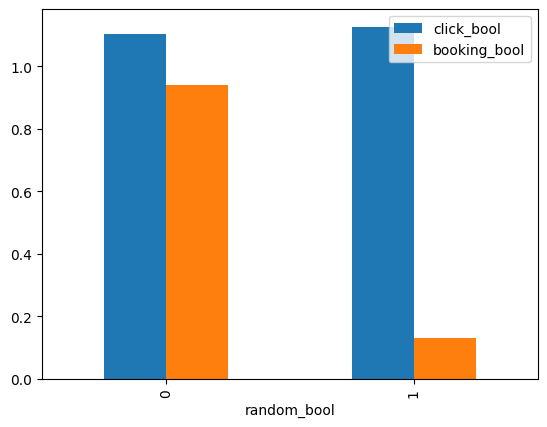

In [86]:
# there are stark differences across the random and non-random subsamples 
dat.groupby(['random_bool', 'srch_id'])[['click_bool', 'booking_bool']].sum().groupby('random_bool').mean().plot.bar()

## Across position in the search list 

In [87]:
dat.groupby('position')[['click_bool', 'booking_bool', 'price_usd', 'prop_starrating']].mean().round(2)

,click_bool,booking_bool,price_usd,prop_starrating
position,,,,
1,0.19,0.14,291.27,3.45
2,0.13,0.09,276.88,3.39
3,0.11,0.07,265.81,3.35
4,0.09,0.06,265.64,3.32
5,0.02,0.01,178.27,3.21
6,0.07,0.05,266.41,3.28
7,0.06,0.04,262.49,3.26
8,0.05,0.03,270.71,3.24
9,0.05,0.03,264.54,3.23


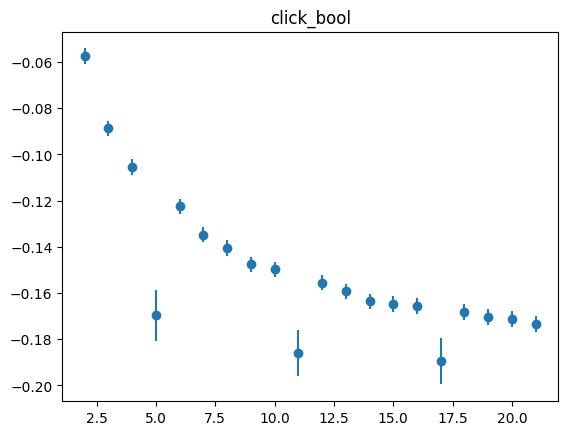

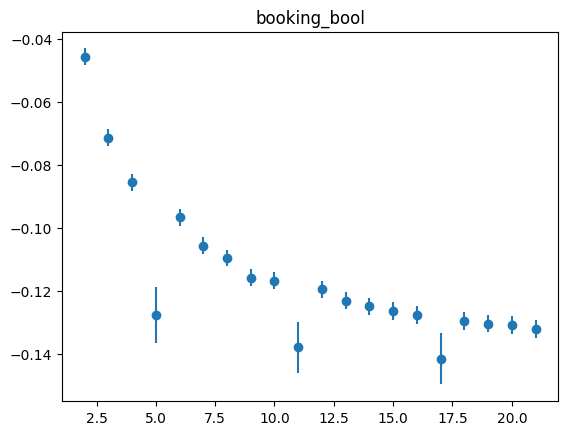

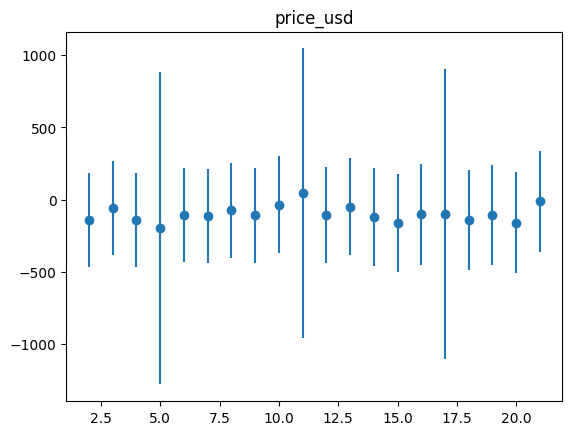

In [ ]:
# let's show the effect of position on the different outcomes as coefficient estimates on dummies with error bars 

# subsample 1% of the sessions
frac = 0.01 
srch_ids = dat['srch_id'].drop_duplicates().sample(frac=frac).sort_values().values
dat_sub = dat[dat['srch_id'].isin(srch_ids)]
dat_sub = dat_sub.query('position <= 21')

def plot_position_dummies(mod): 
    idx_dummies = [c for c in mod.params.index if 'position' in c]
    p_ = mod.params[idx_dummies]
    conf_int = mod.conf_int().loc[idx_dummies]
    plt.errorbar(np.arange(2, p_.size+2), p_.values, yerr=(p_-conf_int[0], conf_int[1]-p_), fmt='o')

# click_bool
mod = ols('click_bool ~ C(position)', data=dat_sub).fit()
plot_position_dummies(mod)
plt.title('click_bool')
plt.show()

# booking_bool
mod = ols('booking_bool ~ C(position)', data=dat_sub).fit()
plot_position_dummies(mod)
plt.title('booking_bool')
plt.show()

# price_usd
mod = ols('price_usd ~ C(position)', data=dat_sub).fit()
plot_position_dummies(mod)
plt.title('price_usd')
plt.show();

# clean up data

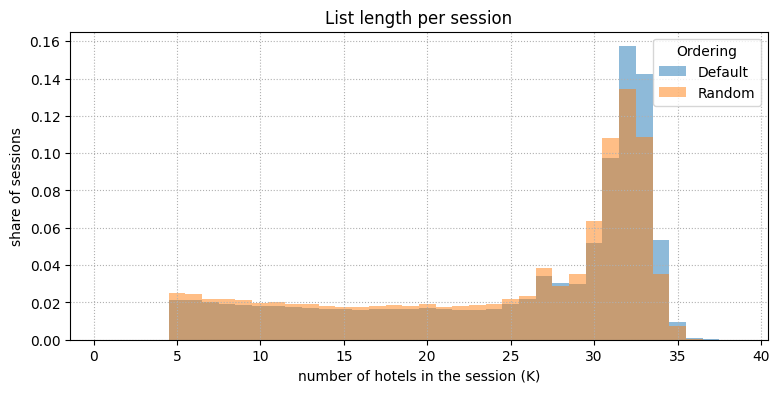

sessions with fewer than 5 hotels: 0.0%
sessions with fewer than 7 hotels: 4.5%
sessions with fewer than 10 hotels: 10.5%
sessions with fewer than 15 hotels: 19.5%


In [89]:
n_list = dat.groupby('srch_id').agg(n_hotels=('position', 'count'),
                                    random_bool=('random_bool', 'max'))

bins = np.arange(0.5, n_list['n_hotels'].max() + 1.5, 1)    # one bar per list length
fig, ax = plt.subplots(figsize=(9, 4))
for rb, name in [(0, 'Default'), (1, 'Random')]:
    ax.hist(n_list.loc[n_list.random_bool == rb, 'n_hotels'], bins=bins,
            density=True, alpha=0.5, label=name)
ax.set_xlabel('number of hotels in the session (K)')
ax.set_ylabel('share of sessions')
ax.set_title('List length per session')
ax.legend(title='Ordering'); ax.grid(linestyle=':')
plt.show()

# how much each cut-off would drop
for k in [5, 7, 10, 15]:
    print(f'sessions with fewer than {k} hotels: {(n_list.n_hotels < k).mean():.1%}')

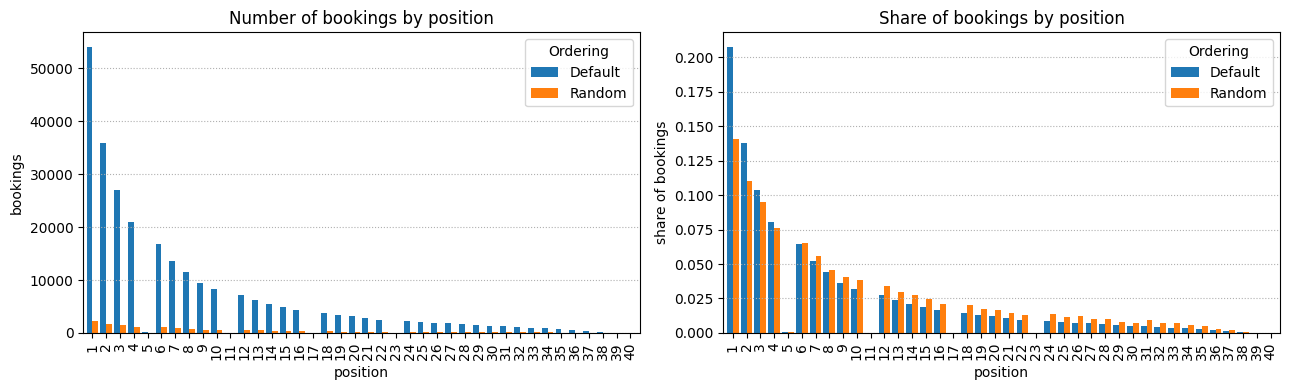

Share of bookings at position 30 or higher:
random_bool
Default    1.4109
Random     2.3793
dtype: float64


In [90]:
b = dat[dat['booking_bool'] == 1]
counts = b.groupby(['position', 'random_bool']).size().unstack('random_bool').fillna(0)
counts = counts.rename(columns={0: 'Default', 1: 'Random'})
shares = counts / counts.sum()                      # share of each ordering's bookings at each position

fig, axs = plt.subplots(1, 2, figsize=(13, 4))

counts.plot(kind='bar', ax=axs[0], width=0.85)
axs[0].set_title('Number of bookings by position'); axs[0].set_ylabel('bookings')

shares.plot(kind='bar', ax=axs[1], width=0.85)
axs[1].set_title('Share of bookings by position'); axs[1].set_ylabel('share of bookings')

for ax in axs:
    ax.set_xlabel('position'); ax.grid(axis='y', linestyle=':')
    ax.legend(title='Ordering')
plt.tight_layout(); plt.show()

print('Share of bookings at position 30 or higher:')
print(((counts[counts.index >= 33].sum() / counts.sum())*100).round(4))

## Pr(buy | search, random)

Arguably, the two most important graphs in Ursu relate to Pr(click) and Pr(buy|click). 

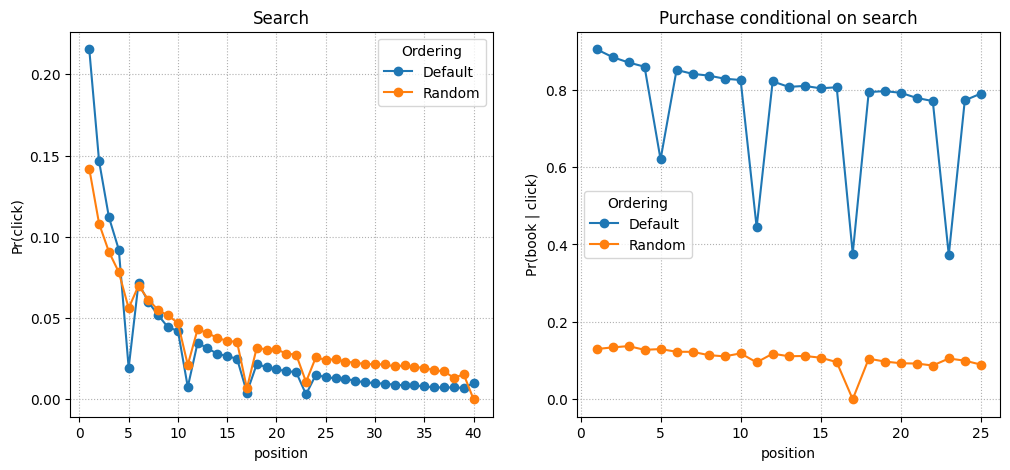

In [91]:
fig, axs = plt.subplots(1, 2, figsize=(12, 5))

# Pr(click)
dat.groupby(['random_bool', 'position'])['click_bool'].mean().unstack('random_bool').rename(columns={0: 'Default', 1: 'Random'}).plot(marker='o', ax=axs[0])
axs[0].legend(title='Ordering'); axs[0].set_ylabel('Pr(click)'); axs[0].grid(axis='both', linestyle=':');
axs[0].set_title('Search'); 

# next: we condition on clicking (i.e. searching) and being in the top 25 positions (the last are very noisy)
df = dat.query('(click_bool == 1) & (position <= 25)')

# Pr(buy | click): the click-through rate (CTR)
df.groupby(['random_bool', 'position'])['booking_bool'].mean().unstack('random_bool').rename(columns={0: 'Default', 1: 'Random'}).plot(marker='o', ax=axs[1])
axs[1].legend(title='Ordering');
axs[1].set_ylabel('Pr(book | click)'); axs[1].grid(axis='both', linestyle=':'); 
axs[1].set_title('Purchase conditional on search');

## Checking if the random ranking is default

We remove sessions with less than 25 listning to be able to compare data with similar length. Otherwise sessions with fewer listnings will influence the mean of earlier positions making the it look like the position influences the variables more than it actually does. 

We could consider whether we wanted to balance the dataset (remove sessions with few listnings and observations with very high position. But it should not matter much for estimation)

In [92]:
### Code to balance the data set ###

K_max = 100   # keep positions 1-29, i.e. drop 30 and higher
K_min = 25    # keep sessions with at least 5 hotels

n_sessions0 = dat['srch_id'].nunique()

# 1. sessions that booked a hotel we are about to drop: remove the whole session
booked_deep = dat.loc[(dat['booking_bool'] == 1) & (dat['position'] > K_max), 'srch_id'].unique()

# 2. drop hotels at position 30 or higher, and those sessions
dat_bal = dat[(dat['position'] <= K_max) & (~dat['srch_id'].isin(booked_deep))].copy()

# 3. drop sessions with fewer than 5 hotels (counted after the cut)
n_hotels = dat_bal.groupby('srch_id')['position'].transform('count')
dat_bal = dat_bal[n_hotels >= K_min]

# what was dropped
print(f"sessions dropped for a booking at position > {K_max}: {len(booked_deep)} ({len(booked_deep)/n_sessions0:.2%})")
print(f"sessions left: {dat_bal['srch_id'].nunique()} of {n_sessions0} ({dat_bal['srch_id'].nunique()/n_sessions0:.1%})")
print(f"rows left: {len(dat_bal)} of {len(dat)} ({len(dat_bal)/len(dat):.1%})")

sessions dropped for a booking at position > 100: 0 (0.00%)
sessions left: 253771 of 399344 (63.5%)
rows left: 7874634 of 9917530 (79.4%)


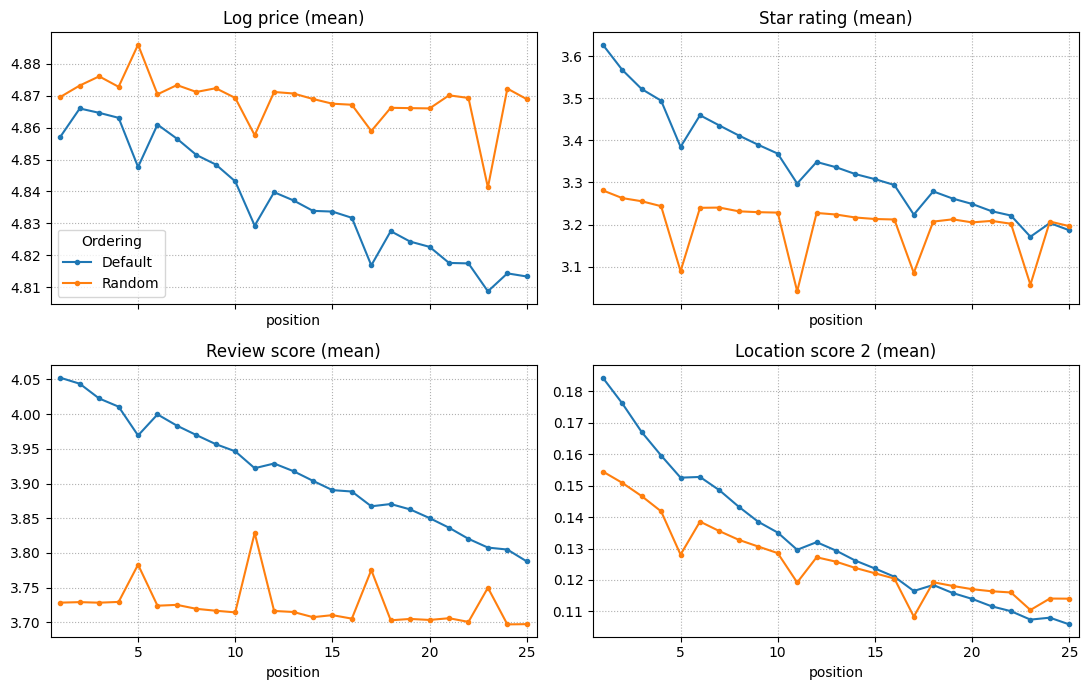

In [93]:
attrs = {'log_price': 'Log price (mean)',
         'prop_starrating': 'Star rating (mean)',
         'prop_review_score': 'Review score (mean)',
         'prop_location_score2': 'Location score 2 (mean)'}

d = dat_bal.query('position <= 25').copy()
d['log_price'] = np.log(d['price_usd'].where(d['price_usd'] > 0))  # zero prices -> NaN

fig, axs = plt.subplots(2, 2, figsize=(11, 7), sharex=True)
axs = axs.flatten()

for ax, (col, label) in zip(axs, attrs.items()):
    for rb, name in [(0, 'Default'), (1, 'Random')]:
        m = d[d.random_bool == rb].groupby('position')[col].mean()
        ax.plot(m.index, m, marker='o', ms=3, label=name)
    ax.set_title(label); ax.set_xlabel('position'); ax.grid(linestyle=':')
    ax.set_xlim(0.5, 25.5)

axs[0].legend(title='Ordering')
plt.tight_layout(); plt.show()

# Micro likelihood

As in PS8 and PS9, the data go in long format, indexed by $(i, j)$: $i$ is the session (`srch_id`) and $j$ the listing's position in it. Each session also gets a row for the outside option, $j = 0$.

$j$ is a label, not a counter: almost every session skips some positions, so never assume that $j$ runs $0, 1, \dots, J$. The position also enters as a regressor, $\text{Rank}_{ij}$, in the column `position_num`.

In [129]:
# hotel mean log price over all sessions (zero prices excluded)
p_ok = dat['price_usd'] > 0
hotel_mean = np.log(dat.loc[p_ok, 'price_usd']).groupby(dat.loc[p_ok, 'prop_id']).mean()
hotel_n    = dat.loc[p_ok].groupby('prop_id').size()


frac = 0.2 # the share of sessions to keep: the full data are slow to estimate on
price_min = dat.groupby('srch_id')['price_usd'].min()
idx_i = price_min.index[price_min > 0] # a few listings have a price of zero, so log price fails: drop their sessions
idx_i = pd.Series(idx_i).sample(frac=frac, random_state=1).values
I_sample = dat['srch_id'].isin(idx_i)
df = dat[I_sample]
df = df.set_index(['srch_id', 'position']).sort_index()
df.index.names = ['i', 'j']
df = df.select_dtypes('number') # numbers only, because the outside rows will be zeros

# the regressors, built before the outside rows go in, so that those rows get zeros
df['log_price'] = np.log(df['price_usd'])
df['stars'] = df['prop_starrating'].astype(float)
df['review'] = df['prop_review_score']
df['position_num'] = df.index.get_level_values('j').astype(float) # Rank_ij
df['position_log'] = np.log(df['position_num']) # log(Rank_ij)
df['constant'] = 1.0

df['constant'] = 1.0
df['hotel_mean_logp'] = df['prop_id'].map(hotel_mean)

### Different position setups ###
# linear position 
df['position_num'] = df.index.get_level_values('j').astype(float) # Rank_ij
#log position
df['position_log'] = np.log(df['position_num']) # log(Rank_ij)
# dummy for each position for testing
pos = df.index.get_level_values('j').to_series(index=df.index).clip(upper=26)   # 26 = "26 or lower"
dummies = pd.get_dummies(pos, prefix='pos', dtype=float).drop(columns='pos_1')   # position 1 = base
df = df.join(dummies)

### regressors for combining random and default sessions
# Dummy for default session (seperate the oversampling /level effect)
df['default_dum'] = (df['random_bool'] == 0).astype(float)
# interaction term between default session and log position (to allow for different position effects in the two subsamples)
df['default_dum_x_position_log'] = df['default_dum'] * df['position_log']
#interaction term between default session and stars
df['default_dum_x_stars'] = df['default_dum'] * df['stars']


# price outliers: drop sessions with a listing above 10x the session median
med = df.groupby(level='i')['price_usd'].transform('median')
bad = df.loc[df['price_usd'] > 10 * med].index.get_level_values('i').unique()
df = df[~df.index.get_level_values('i').isin(bad)]

# missing codes: 0 stars = unknown, 0 reviews = no reviews
df['stars_missing']  = (df['prop_starrating'] == 0).astype(float)
df['review_missing'] = (df['prop_review_score'] == 0).astype(float)

# per-stay prices and the hotel's usual price
df['hist_missing'] = (df['prop_log_historical_price'] == 0).astype(float)


# the outside option: one row per session, j = 0, with every column zero, so delta_i0 = 0
idx_outside = pd.MultiIndex.from_product([df.index.get_level_values('i').unique(), [0]], names=['i', 'j'])
df = df.reindex(df.index.append(idx_outside), fill_value=0).sort_index()

I_outside = df.index.get_level_values('j') == 0
booked_any = df.groupby(level='i')['booking_bool'].transform('max') # 1 if the session booked a hotel
booked_any = booked_any[I_outside]
df.loc[I_outside, 'click_bool'] = 1 # the outside option is always "searched", as in PS8
df.loc[I_outside, 'booking_bool'] = 1 - booked_any # and it is chosen when no hotel is booked

# make random_ bool for outside option = 1 if session is random rank (right now it is 0)
df['random_bool'] = df.groupby(level='i')['random_bool'].transform('max')

assert (df.groupby(level='i')['booking_bool'].sum() == 1).all() # exactly one choice per session

df.head(10)

random_bool  click_bool  booking_bool  price_usd  prop_starrating  \
i j                                                                       
4 0             1           1             1        0.0                0   
  1             1           0             0      159.0                3   
  2             1           0             0      219.0                3   
  3             1           0             0      365.0                4   
  4             1           0             0      329.0                3   
  6             1           0             0      330.0                4   
  7             1           0             0      135.0                2   
  8             1           0             0      189.0                2   
  9             1           0             0      329.0                4   
  10            1           0             0      335.0                4   

      prop_review_score  prop_brand_bool  prop_location_score1  \
i j                                                              
4 0                 0.0                0                  0.00   
  1                 4.0                1                  1.61   
  2                 3.5                0                  3.26   
  3                 4.0                1                  3.09   
  4                 4.0                0                  3.26   
  6                 4.0                1                  3.18   
  7                 4.0                1                  0.69   
  8                 3.5                0                  3.22   
  9                 4.5                1                  3.09   
  10                4.5                1                  1.10   

      prop_location_score2  prop_log_historical_price  ...  pos_23  pos_24  \
i j                                                    ...                   
4 0                 0.0000                       0.00  ...     0.0     0.0   
  1                 0.0969                       5.28  ...     0.0     0.0   
  2                 0.3431                       5.60  ...     0.0     0.0   
  3                 0.1692                       5.69  ...     0.0     0.0   
  4                 0.3729                       5.74  ...     0.0     0.0   
  6                 0.3483                       5.92  ...     0.0     0.0   
  7                 0.0408                       5.14  ...     0.0     0.0   
  8                 0.3696                       5.52  ...     0.0     0.0   
  9                 0.1417                       5.92  ...     0.0     0.0   
  10                0.0149                       5.55  ...     0.0     0.0   

      pos_25  pos_26  default_dum  default_dum_x_position_log  \
i j                                                             
4 0      0.0     0.0          0.0                         0.0   
  1      0.0     0.0          0.0                         0.0   
  2      0.0     0.0          0.0                         0.0   
  3      0.0     0.0          0.0                         0.0   
  4      0.0     0.0          0.0                         0.0   
  6      0.0     0.0          0.0                         0.0   
  7      0.0     0.0          0.0                         0.0   
  8      0.0     0.0          0.0                         0.0   
  9      0.0     0.0          0.0                         0.0   
  10     0.0     0.0          0.0                         0.0   

      default_dum_x_stars  stars_missing  review_missing  hist_missing  
i j                                                                     
4 0                   0.0            0.0             0.0           0.0  
  1                   0.0            0.0             0.0           0.0  
  2                   0.0            0.0             0.0           0.0  
  3                   0.0            0.0             0.0           0.0  
  4                   0.0            0.0             0.0           0.0  
  6                   0.0            0.0             0.0           0.0  
  7       

In [131]:
### Random 
# filter on random_bool = 1, i.e. the random ranking subsample
df_rand = df[df['random_bool'] == 1]

# drop the sessions where any hotel has a missing review, and note what is dropped
miss_review = df_rand['review'].isna().groupby(level='i').transform('any')
n_sess, n_rows = df_rand.index.get_level_values('i').nunique(), len(df_rand)
drop_sess = df_rand[miss_review].index.get_level_values('i').unique()
print(f'hotel rows with missing review: {df_rand["review"].isna().sum()}')
print(f'sessions dropped: {len(drop_sess)} of {n_sess} ({len(drop_sess)/n_sess:.1%})')
print(f'rows dropped (incl. outside rows): {miss_review.sum()} of {n_rows} ({miss_review.sum()/n_rows:.1%})')
print(f'bookings in dropped sessions: {df_rand.loc[miss_review & (df_rand.index.get_level_values("j") > 0), "booking_bool"].sum()}')
df_rand = df_rand[~miss_review]
I_chosen_rand = df_rand['booking_bool'] == 1

# chose beta variables to include
xvars = ['log_price', 'stars', 'stars_missing', 'position_num', 'review', 'review_missing',
         'prop_brand_bool', 'prop_location_score1', 'promotion_flag', 'hist_missing', 'hotel_mean_logp', 'constant']
X_rand = df_rand[xvars].astype(float)

res_baseline = minimize(loglike, np.zeros(len(xvars)), args=(X_rand, I_chosen_rand), method='BFGS')
print(res_baseline.message)
print("Random ranking subsample estimates:")

LL = -res_baseline.fun
print(f"\nLog-likelihood: {LL:.2f}")

theta_baseline = pd.Series(res_baseline.x, xvars)
theta_baseline.round(3)

hotel rows with missing review: 1190
sessions dropped: 882 of 23973 (3.7%)
rows dropped (incl. outside rows): 23240 of 603498 (3.9%)
bookings in dropped sessions: 94
Optimization terminated successfully.
Random ranking subsample estimates:

Log-likelihood: -0.77


log_price              -1.042
stars                   0.199
stars_missing           0.162
position_num           -0.078
review                  0.211
review_missing         -0.183
prop_brand_bool         0.416
prop_location_score1   -0.038
promotion_flag          0.210
hist_missing            0.050
hotel_mean_logp         0.401
constant               -2.605
dtype: float64

## The logit

The likelihood is the one in PS9 with $\gamma = 0$, so $\hat\beta$ estimates $\theta = \beta - \gamma$. `groupby(level='i')` does the sums within each session. `.transform('max')` returns the session's maximum on every row of the session, so it can be subtracted from `v`, while `.max()` would return one number per session.

In [95]:
def loglike(beta, X, I_chosen):
    '''Minus the average log-likelihood of the logit.'''
    v = X @ beta
    v -= v.groupby(level='i').transform('max') # for numerical stability
    log_probs = v - np.log(np.exp(v).groupby(level='i').transform('sum'))
    return -np.mean(log_probs[I_chosen].values)


# Testing different descision for the setup of the baseline model
 - examines how position should enter in the estimation (log or linear)
 - examines what data to use (random ranking, defualt ranking or both)

### Testing how position should enter the regression

In [96]:
# filter on random_bool = 1, i.e. the random ranking subsample
df_rand = df[df['random_bool'] == 1]
I_chosen_rand = df_rand['booking_bool'] == 1

In [97]:
### Check the sessions: zero clicks and more than one booking
# the default (Expedia) sample has at least one click in every session, the random sample might not.
# the hotel rows only (j > 0), since the outside rows were given click_bool = 1 above

def session_check(d):
    """Per-session counts of clicks and bookings over the hotel rows, and a summary of the odd cases."""
    hotels = d[d.index.get_level_values('j') > 0]
    s = hotels.groupby(level='i').agg(random_bool=('random_bool', 'max'),
                                       n_clicks=('click_bool', 'sum'),
                                       n_books=('booking_bool', 'sum'))
    summary = s.groupby('random_bool').agg(
        sessions=('n_clicks', 'size'),
        zero_clicks=('n_clicks', lambda x: (x == 0).sum()),
        multi_books=('n_books', lambda x: (x > 1).sum()),
        no_booking=('n_books', lambda x: (x == 0).sum()))
    summary['zero_clicks_%'] = (100 * summary['zero_clicks'] / summary['sessions']).round(2)
    summary['multi_books_%'] = (100 * summary['multi_books'] / summary['sessions']).round(2)
    summary['no_booking_%'] = (100 * summary['no_booking'] / summary['sessions']).round(2)
    return s, summary.rename(index={0: 'Default', 1: 'Random'})

# full data (dat has no outside rows, so index it the same way first)
s_full, summary_full = session_check(dat.set_index(['srch_id', 'position']).rename_axis(['i', 'j']))
print('Full data:')
display(summary_full)

# the estimation sample
s_est, summary_est = session_check(df)
print('Estimation sample (df):')
display(summary_est)

# bookings without a click would also be odd
hotels_rand = df_rand[df_rand.index.get_level_values('j') > 0]
print('random sample, bookings without a click:', ((hotels_rand['booking_bool'] == 1) & (hotels_rand['click_bool'] == 0)).sum())
print('random sample, distribution of bookings per session:')
print(s_est.loc[s_est.random_bool == 1, 'n_books'].value_counts().sort_index())


Full data:


,sessions,zero_clicks,multi_books,no_booking,zero_clicks_%,multi_books_%,no_booking_%
random_bool,,,,,,,
Default,277798,0,0,17050,0.0,0.0,6.14
Random,121546,0,0,105701,0.0,0.0,86.96


Estimation sample (df):


,sessions,zero_clicks,multi_books,no_booking,zero_clicks_%,multi_books_%,no_booking_%
random_bool,,,,,,,
Default,27839,0,0,1739,0.0,0.0,6.25
Random,12095,0,0,10451,0.0,0.0,86.41


random sample, bookings without a click: 0
random sample, distribution of bookings per session:
n_books
0    10451
1     1644
Name: count, dtype: int64


In [98]:
### Random with linear position

# chose beta variables to include
xvars = ['log_price', 'stars', 'position_num', 'constant']
X_rand_lin = df_rand[xvars].astype(float)

res_base_rand_lin = minimize(loglike, np.zeros(len(xvars)), args=(X_rand_lin, I_chosen_rand), method='BFGS')
print(res_base_rand_lin.message)
print("Random ranking subsample estimates:")
pd.Series(res_base_rand_lin.x, xvars).round(3)

Optimization terminated successfully.
Random ranking subsample estimates:


log_price      -0.677
stars           0.267
position_num   -0.075
constant       -1.647
dtype: float64

In [99]:
### Random with log position

# chose beta variables to include
xvars = ['log_price', 'stars', 'position_log', 'constant']
X_rand_log = df_rand[xvars].astype(float)

res_base_rand_log = minimize(loglike, np.zeros(len(xvars)), args=(X_rand_log, I_chosen_rand), method='BFGS')
print(res_base_rand_log.message)
print("Random ranking subsample estimates:")
pd.Series(res_base_rand_log.x, xvars).round(3)

Optimization terminated successfully.
Random ranking subsample estimates:


log_price      -0.669
stars           0.266
position_log   -0.636
constant       -1.275
dtype: float64

In [100]:
# ### Random with position dummies
# dummy_cols = list(dummies.columns)  

# xvars = ['log_price', 'stars', 'constant'] + dummy_cols
# X_rand_dum = df_rand[xvars].astype(float)

# res_base_rand_dum = minimize(loglike, np.zeros(len(xvars)), args=(X_rand_dum, I_chosen_rand), method='BFGS')
# print(res_base_rand_dum.message)
# print("Random ranking subsample estimates:")
# #pd.Series(res_base_rand_dum.x, xvars).round(3)

In [101]:
# th_lin = pd.Series(res_base_rand_lin.x, ['log_price', 'stars', 'position_num', 'constant'])
# th_log = pd.Series(res_base_rand_log.x, ['log_price', 'stars', 'position_log', 'constant'])
# th_dum = pd.Series(res_base_rand_dum.x, ['log_price', 'stars', 'constant'] + dummy_cols)

# r = np.arange(1, 26)                                                          # positions 1-25
# coef_dum = np.r_[0.0, th_dum[[f'pos_{k}' for k in range(2, 26)]].values]     # position 1 = 0 (base)

# plt.plot(r, coef_dum, 'o-', label='Dummies')
# plt.plot(r, th_lin['position_num'] * (r - 1), '--', label='Linear')          # normalized to 0 at position 1
# plt.plot(r, th_log['position_log'] * np.log(r), '--', label='Log')            # log(1) = 0 already
# plt.axhline(0, color='grey', lw=0.8)
# plt.xlabel('position')
# plt.ylabel('utility relative to position 1')
# plt.title('Estimated position effects, Random sessions')
# plt.legend(); plt.grid(linestyle=':')
# plt.show()

Below we look at the default ranking subsample

In [102]:
# # filter on random_bool = 0, i.e. the defualt ranking subsample
# df_def = df[df['random_bool'] == 0]
# I_chosen_def = df_def['booking_bool'] == 1

# ### Default with linear position

# # chose beta variables to include
# xvars = ['log_price', 'stars', 'position_num', 'constant']
# X_def_lin = df_def[xvars].astype(float)

# res_base_def_lin = minimize(loglike, np.zeros(len(xvars)), args=(X_def_lin, I_chosen_def), method='BFGS')
# print(res_base_def_lin.message)
# print("Default ranking subsample estimates:")
# pd.Series(res_base_def_lin.x, xvars).round(3)

# ### default with log position

# # chose beta variables to include
# xvars = ['log_price', 'stars', 'position_log', 'constant']
# X_def_log = df_def[xvars].astype(float)

# res_base_def_log = minimize(loglike, np.zeros(len(xvars)), args=(X_def_log, I_chosen_def), method='BFGS')
# print(res_base_def_log.message)
# print("Default ranking subsample estimates:")
# pd.Series(res_base_def_log.x, xvars).round(3)

# ### default with position dummies
# dummy_cols = list(dummies.columns)  

# xvars = ['log_price', 'stars', 'constant'] + dummy_cols
# X_def_dum = df_def[xvars].astype(float)

# res_base_def_dum = minimize(loglike, np.zeros(len(xvars)), args=(X_def_dum, I_chosen_def), method='BFGS')
# print(res_base_def_dum.message)
# print("Default ranking subsample estimates:")
# #pd.Series(res_base_def_dum.x, xvars).round(3)

In [103]:
# th_lin = pd.Series(res_base_def_lin.x, ['log_price', 'stars', 'position_num', 'constant'])
# th_log = pd.Series(res_base_def_log.x, ['log_price', 'stars', 'position_log', 'constant'])
# th_dum = pd.Series(res_base_def_dum.x, ['log_price', 'stars', 'constant'] + dummy_cols)

# r = np.arange(1, 26)                                                          # positions 1-25
# coef_dum = np.r_[0.0, th_dum[[f'pos_{k}' for k in range(2, 26)]].values]     # position 1 = 0 (base)

# plt.plot(r, coef_dum, 'o-', label='Dummies')
# plt.plot(r, th_lin['position_num'] * (r - 1), '--', label='Linear')          # normalized to 0 at position 1
# plt.plot(r, th_log['position_log'] * np.log(r), '--', label='Log')            # log(1) = 0 already
# plt.axhline(0, color='grey', lw=0.8)
# plt.xlabel('position')
# plt.ylabel('utility relative to position 1')
# plt.title('Estimated position effects, Default sessions')
# plt.legend(); plt.grid(linestyle=':')
# plt.show()

### Testing using both random and default data

In [104]:
# both random and default with default dummy (absorbs the level difference)
I_chosen = df['booking_bool'] == 1

# chose beta variables to include
xvars_both = ['log_price', 'stars', 'position_log', 'default_dum', 'constant']
X_both = df[xvars_both].astype(float)

res_base_both = minimize(loglike, np.zeros(len(xvars_both)), args=(X_both, I_chosen), method='BFGS')
print(res_base_both.message)
print("Both rankings  estimates:")
pd.Series(res_base_both.x, xvars_both).round(3)

Optimization terminated successfully.
Both rankings  estimates:


log_price      -0.955
stars           0.301
position_log   -0.815
default_dum     4.641
constant        0.252
dtype: float64

In [105]:
# both random and default with default dummy (absorbs the level difference) and position interaction term (allows for different position effects)
I_chosen = df['booking_bool'] == 1

# chose beta variables to include
xvars_both = ['log_price', 'stars', 'position_log', 'default_dum', 'default_dum_x_position_log', 'constant']
X_both = df[xvars_both].astype(float)

res_base_both = minimize(loglike, np.zeros(len(xvars_both)), args=(X_both, I_chosen), method='BFGS')
print(res_base_both.message)
print("Both rankings  estimates:")
pd.Series(res_base_both.x, xvars_both).round(3)

Optimization terminated successfully.
Both rankings  estimates:


log_price                    -0.954
stars                         0.297
position_log                 -0.637
default_dum                   4.954
default_dum_x_position_log   -0.190
constant                     -0.037
dtype: float64

In [106]:
# both random and default with default dummy (absorbs the level difference) and position interaction term (allows for different position effects) and stars interaction term (as this differs from the random estimates)
I_chosen = df['booking_bool'] == 1

# chose beta variables to include
xvars_both = ['log_price', 'stars', 'position_log', 'default_dum', 'default_dum_x_position_log', 'default_dum_x_stars', 'constant']
X_both = df[xvars_both].astype(float)

res_base_both = minimize(loglike, np.zeros(len(xvars_both)), args=(X_both, I_chosen), method='BFGS')
print(res_base_both.message)
print("Both rankings  estimates:")
pd.Series(res_base_both.x, xvars_both).round(3)

Optimization terminated successfully.
Both rankings  estimates:


log_price                    -0.955
stars                         0.360
position_log                 -0.635
default_dum                   5.184
default_dum_x_position_log   -0.193
default_dum_x_stars          -0.070
constant                     -0.239
dtype: float64

In [111]:
### Random 
# filter on random_bool = 1, i.e. the random ranking subsample
df_rand = df[df['random_bool'] == 1]
I_chosen_rand = df_rand['booking_bool'] == 1

# chose beta variables to include
xvars = ['log_price', 'stars', 'position_log', 'constant']
X_rand = df_rand[xvars].astype(float)

res_base_rand = minimize(loglike, np.zeros(len(xvars)), args=(X_rand, I_chosen_rand), method='BFGS')
print(res_base_rand.message)
print("Random ranking subsample estimates:")
pd.Series(res_base_rand.x, xvars).round(3)

Optimization terminated successfully.
Random ranking subsample estimates:


log_price      -0.867
stars           0.354
position_log   -0.653
constant       -0.639
dtype: float64

In [108]:
### defualt 
# filter on random_bool = 1, i.e. the random ranking subsample
df_def = df[df['random_bool'] == 0]
I_chosen_def = df_def['booking_bool'] == 1

# chose beta variables to include
xvars = ['log_price', 'stars', 'position_log', 'constant']
X_def = df_def[xvars].astype(float)

res_base_def = minimize(loglike, np.zeros(len(xvars)), args=(X_def, I_chosen_def), method='BFGS')
print(res_base_def.message)
print("Default ranking subsample estimates:")
pd.Series(res_base_def.x, xvars).round(3)

Optimization terminated successfully.
Default ranking subsample estimates:


log_price      -1.009
stars           0.307
position_log   -0.827
constant        5.155
dtype: float64

# Estimating the chosen baseline model
This model uses log_postition and random ranking data

In [ ]:
### Random 
# filter on random_bool = 1, i.e. the random ranking subsample
df_rand = df[df['random_bool'] == 1]

# drop the sessions where any hotel has a missing review, and note what is dropped
miss_review = df_rand['review'].isna().groupby(level='i').transform('any')
n_sess, n_rows = df_rand.index.get_level_values('i').nunique(), len(df_rand)
drop_sess = df_rand[miss_review].index.get_level_values('i').unique()
print(f'hotel rows with missing review: {df_rand["review"].isna().sum()}')
print(f'sessions dropped: {len(drop_sess)} of {n_sess} ({len(drop_sess)/n_sess:.1%})')
print(f'rows dropped (incl. outside rows): {miss_review.sum()} of {n_rows} ({miss_review.sum()/n_rows:.1%})')
print(f'bookings in dropped sessions: {df_rand.loc[miss_review & (df_rand.index.get_level_values("j") > 0), "booking_bool"].sum()}')
df_rand = df_rand[~miss_review]
I_chosen_rand = df_rand['booking_bool'] == 1

# chose beta variables to include
xvars = ['log_price', 'stars', 'position_num', 'review', 'prop_brand_bool', 'prop_location_score1', 'promotion_flag', 'prop_log_historical_price', 'constant']
X_rand = df_rand[xvars].astype(float)

res_baseline = minimize(loglike, np.zeros(len(xvars)), args=(X_rand, I_chosen_rand), method='BFGS')
print(res_baseline.message)
print("Random ranking subsample estimates:")

LL = -res_baseline.fun
print(f"\nLog-likelihood: {LL:.2f}")

theta_baseline = pd.Series(res_baseline.x, xvars)
theta_baseline.round(3)

hotel rows with missing review: 4348
sessions dropped: 3488 of 138922 (2.5%)
rows dropped (incl. outside rows): 89317 of 3631330 (2.5%)
bookings in dropped sessions: 3255
Optimization terminated successfully.
Random ranking subsample estimates:

Log-likelihood: -2.74


log_price                   -1.205
stars                        0.282
position_num                -0.106
review                       0.210
prop_brand_bool              0.149
prop_location_score1         0.060
promotion_flag               0.084
prop_log_historical_price    0.044
constant                     4.472
dtype: float64

## Computing price equivalent
#### what it is worth to a hotel to move one position higher, measured as the price change that would keep its booking probability constant&

In [115]:
### Price change (in log price) that keeps booking probability constant when a hotel moves up one slot
def price_change(theta, pos, pos_type='lin'):
    if pos_type == 'lin':
        delta_pos = (pos - 1) - pos                    # new − old = −1
        theta_pos = theta['position_num']
    elif pos_type == 'log':
        delta_pos = np.log(pos - 1) - np.log(pos)      # new − old, negative
        theta_pos = theta['position_log']
    return -theta_pos / theta['log_price'] * delta_pos

In [116]:
pos = 2
dlogp = price_change(theta_baseline, pos, pos_type='lin')
print(f"Moving from position {pos} to {pos-1}: Δ log price = {dlogp:.3f} "
      f"(price increase of {100*(np.exp(dlogp)-1):.1f}%)")

Moving from position 2 to 1: Δ log price = 0.066 (price increase of 6.8%)


In [ ]:
# use this if log position is used in the model

# positions = range(2, 26)
# dlogp = np.array([price_change(theta_baseline, pos, pos_type = 'lin') for pos in positions])

# table = pd.DataFrame({
#     'Move': [f'{p} → {p-1}' for p in positions],
#     'Δ log price': dlogp.round(3),
#     'Price increase (%)': (100 * (np.exp(dlogp) - 1)).round(1),
# }).set_index('Move')

# table

## compute the markup
Markup for each hotel listning is given by

$\eta_j = p_j \cdot L_j = \frac{p_j}{\alpha(1-s_j)}$.

The Lerner index is given by $\frac{1}{\alpha}$.

In [ ]:
def predict_shares(theta, d):
    """
    theta: pd.Series of estimates, indexed by variable name (e.g. pd.Series(res.x, xvars))
    d:     long data with index (i, j), including the outside rows (j = 0)
    returns: pd.Series of s_ij, one per row
    """
    v = d[list(theta.index)].astype(float) @ theta.values          # utility x_ij' theta (outside rows: 0)
    v = v - v.groupby(level='i').transform('max')                  # numerical stability; shares unchanged
    ev = np.exp(v)
    return ev / ev.groupby(level='i').transform('sum')             # logit share within each session

def compute_markups(theta, d):
    """
    Markups implied by the log-price coefficient (single-product Bertrand FOC).
    theta: pd.Series of estimates indexed by variable name (unrounded)
    d:     long data with index (i, j), incl. outside rows (j = 0) and 'price_usd'
    """
    alpha = -theta['log_price']
    d = d.copy()
    d['s'] = predict_shares(theta, d)

    hotels = d[d.index.get_level_values('j') > 0].copy()           # hotels only
    hotels['markup'] = hotels['price_usd'] / (alpha * (1 - hotels['s']))
    hotels['lerner'] = hotels['markup'] / hotels['price_usd']      # (p - c) / p
    hotels['mc']     = hotels['price_usd'] - hotels['markup']       # implied marginal cost

    summary = hotels[['price_usd', 'markup', 'mc', 'lerner']].agg(['mean', 'median']).T
    return hotels, summary.round(3)

In [ ]:
hotels_base, summary_base = compute_markups(theta_baseline, df_rand)
summary_base.round(2).T

,price_usd,markup,mc,lerner
mean,164.57,142.96,21.61,0.87
median,125.01,109.10,16.28,0.87


# Estimating the extended model
This model uses linear postition and random ranking data.

We use search data, and the two-step simulated least squares to estimate search costs (method described on p. 45 in demand note and also the method used in PS9)

In [145]:
### Random 
# filter on random_bool = 1, i.e. the random ranking subsample
df_rand = df[df['random_bool'] == 1]

# drop the sessions where any hotel has a missing review, and note what is dropped
miss_review = df_rand['review'].isna().groupby(level='i').transform('any')
n_sess, n_rows = df_rand.index.get_level_values('i').nunique(), len(df_rand)
drop_sess = df_rand[miss_review].index.get_level_values('i').unique()
print(f'hotel rows with missing review: {df_rand["review"].isna().sum()}')
print(f'sessions dropped: {len(drop_sess)} of {n_sess} ({len(drop_sess)/n_sess:.1%})')
print(f'rows dropped (incl. outside rows): {miss_review.sum()} of {n_rows} ({miss_review.sum()/n_rows:.1%})')
print(f'bookings in dropped sessions: {df_rand.loc[miss_review & (df_rand.index.get_level_values("j") > 0), "booking_bool"].sum()}')
df_rand = df_rand[~miss_review]
I_chosen_rand = df_rand['booking_bool'] == 1

hotel rows with missing review: 1190
sessions dropped: 882 of 23973 (3.7%)
rows dropped (incl. outside rows): 23240 of 603498 (3.9%)
bookings in dropped sessions: 94


In [146]:
### Setup: map the PS9 objects onto the random-ranking sample
from ps8_tools import simulate_search
from itertools import product
from tqdm import tqdm


X_ext = df_rand[xvars].astype(float) # same X as the baseline, outside rows are zeros
assert not X_ext.isna().any().any(), 'X has missing values: handle them before simulating'

# a_ij: the clicks in the data, inside options only (the outside rows were set to click_bool = 1)
I_inside = X_ext.index.get_level_values('j') > 0
a_data = df_rand.loc[I_inside, 'click_bool'].astype(float)

def gamma_from(gamma_0, gamma_pos, pos_type='lin'):
    """gamma over the columns of X: zero except on the constant and on position_log."""
    gamma = pd.Series(0.0, xvars)
    if pos_type == 'lin':
        gamma['position_num'] = gamma_pos
    elif pos_type == 'log':
        gamma['position_log'] = gamma_pos
    gamma['constant'] = gamma_0
    assert list(gamma.index) == list(xvars), 'position variable not in xvars: check pos_type'

    return gamma


In [147]:
R = 10 # start small (e.g. R = 2) to check that it runs
rng = np.random.default_rng(7)
eps_draws = [pd.Series(rng.gumbel(size=len(X_ext)), X_ext.index) for r in range(R)] # one draw per (i, j), outside rows included


def simulated_searches(delta, mu, eps, seed):
    """a_ij^(r): one simulated search dummy for every session and inside option."""
    d_, searched_ = simulate_search(delta, mu, eps, seed=seed)
    I_inside_ = searched_.index.get_level_values('j') > 0 # the outside option is always "searched"
    searched_ = searched_[I_inside_]
    return searched_

def grid_search(X_, theta_, a_data_, eps_draws_, pos_type='lin'):
    """Q(gamma | theta_) at every grid point, conditioning on >= 1 search per session."""
    rows = []
    for g0, gp in tqdm(list(product(g0_grid, gp_grid)), desc=f'grid, R = {len(eps_draws_)}'):
        gamma = gamma_from(g0, gp, pos_type)
        beta = theta_ + gamma
        a_sim = pd.concat([simulated_searches(X_ @ beta, X_ @ gamma, eps, seed=3 + r)
                           for r, eps in enumerate(eps_draws_)], axis=1).astype(float)
        any_search = a_sim.groupby(level='i').transform('max')
        a_bar = (a_sim * any_search).sum(axis=1) / any_search.sum(axis=1)
        Q = ((a_data_ - a_bar) ** 2).mean()
        rows.append({'gamma_0': g0, 'gamma_pos': gp, 'Q': Q})
    return pd.DataFrame(rows)

def sim_click_rate(theta_, X_, g0, gp, pos_type='lin', R=10):
    gamma = gamma_from(g0, gp, pos_type)
    beta = theta_ + gamma
    a_sim = pd.concat([simulated_searches(X_ @ beta, X_ @ gamma, eps, seed=3 + r)
                       for r, eps in enumerate(eps_draws[:R])], axis=1).astype(float)
    any_search = a_sim.groupby(level='i').transform('max')
    a_bar = (a_sim * any_search).sum(axis=1) / any_search.sum(axis=1)
    return a_bar.groupby(level='j').mean()

### course search for gamma

In [148]:
# make grid such that it searches in relevant ranges ()
gp_c= -theta_baseline['position_num']
gp_grid = list(np.round(gp_c * np.array([0, 0.5, 1.0, 1.5, 2.0]), 3))
g0_grid = [1, 2, 3, 4, 5, 6, 8]


tab_grid = grid_search(X_ext, theta_baseline, a_data, eps_draws)
tab_grid.pivot(index='gamma_0', columns='gamma_pos', values='Q').round(5)

grid, R = 10:   0%|          | 0/35 [00:00<?, ?it/s]

grid, R = 10:   0%|          | 0/35 [00:00<?, ?it/s]


AssertionError: position variable not in xvars: check pos_type

In [ ]:
# the minimum, and the split of theta into taste (beta) and search cost (gamma)
best = tab_grid.loc[tab_grid['Q'].idxmin()]
gamma_0_hat, gamma_pos_hat = best['gamma_0'], best['gamma_pos']
gamma_hat = gamma_from(gamma_0_hat, gamma_pos_hat)
beta_hat = theta_baseline + gamma_hat
pd.DataFrame({'theta (baseline)': theta_baseline, 'gamma (search cost)': gamma_hat, 'beta (taste)': beta_hat}).round(3)

,theta (baseline),gamma (search cost),beta (taste)
log_price,-1.156,0.000,-1.156
stars,0.342,0.000,0.342
position_num,-0.076,0.038,-0.038
review,0.353,0.000,0.353
prop_brand_bool,0.438,0.000,0.438
prop_location_score1,-0.028,0.000,-0.028
promotion_flag,0.270,0.000,0.270
constant,-1.286,3.000,1.714


gamma_0      3.000000
gamma_pos    0.038000
Q            0.044524
Name: 11, dtype: float64


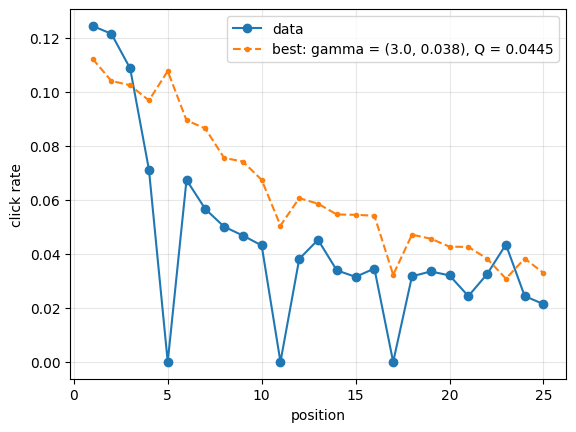

In [ ]:
best = tab_grid.loc[tab_grid['Q'].idxmin()]
print(best)

a_data.groupby(level='j').mean().loc[1:25].plot(marker='o', label='data')
sim_click_rate(best['gamma_0'], best['gamma_pos'], R=len(eps_draws)).loc[1:25].plot(
    ls='--', marker='.',
    label=f"best: gamma = ({best['gamma_0']}, {best['gamma_pos']}), Q = {best['Q']:.4f}")
plt.xlabel('position'); plt.ylabel('click rate')
plt.legend(); plt.grid(alpha=0.3); plt.show()

## Compute model with log position

In [149]:

xvars = ['log_price', 'stars', 'position_log', 'review',
         'prop_brand_bool', 'prop_location_score1', 'promotion_flag', 'hotel_mean_logp', 'constant']
X_log = df_rand[xvars].astype(float)
assert not X_log.isna().any().any()

res_log = minimize(loglike, np.zeros(len(xvars)), args=(X_log, I_chosen_rand), method='BFGS')
print(res_log.message)
theta_log = pd.Series(res_log.x, xvars)
N = df_rand.index.get_level_values('i').nunique()
print(f"Log-likelihood: {-res_log.fun * N:.2f}")
theta_log.round(3)

Optimization terminated successfully.
Log-likelihood: -17826.47


log_price              -1.015
stars                   0.180
position_log           -0.658
review                  0.238
prop_brand_bool         0.411
prop_location_score1   -0.034
promotion_flag          0.207
hotel_mean_logp         0.381
constant               -2.270
dtype: float64

In [144]:

xvars = ['log_price', 'stars', 'stars_missing', 'position_log', 'review', 'review_missing',
         'prop_brand_bool', 'prop_location_score1', 'promotion_flag', 'hotel_mean_logp', 'constant']
X_log = df_rand[xvars].astype(float)
assert not X_log.isna().any().any()

res_log = minimize(loglike, np.zeros(len(xvars)), args=(X_log, I_chosen_rand), method='BFGS')
print(res_log.message)
theta_log = pd.Series(res_log.x, xvars)
N = df_rand.index.get_level_values('i').nunique()
print(f"Log-likelihood: {-res_log.fun * N:.2f}")
theta_log.round(3)

Optimization terminated successfully.
Log-likelihood: -17825.75


log_price              -1.016
stars                   0.197
stars_missing           0.161
position_log           -0.659
review                  0.216
review_missing         -0.158
prop_brand_bool         0.413
prop_location_score1   -0.036
promotion_flag          0.204
hotel_mean_logp         0.378
constant               -2.213
dtype: float64

In [141]:

gp_c = -theta_log['position_log']
gp_grid = list(np.round(gp_c * np.array([0, 0.5, 1.0, 1.5, 2.0]), 3))
g0_grid = [0.5, 1, 2, 2.5, 3, 3.2, 3.5, 4]

tab_grid_log = grid_search(X_log, theta_log, a_data, eps_draws, pos_type='log')
tab_grid_log.pivot(index='gamma_0', columns='gamma_pos', values='Q').round(5)

grid, R = 10:   0%|          | 0/40 [00:00<?, ?it/s]

grid, R = 10: 100%|██████████| 40/40 [05:35<00:00,  8.40s/it]


gamma_pos,0.000,0.329,0.659,0.988,1.317
gamma_0,,,,,
0.5,0.38281,0.12329,0.07515,0.06542,0.06446
1.0,0.17205,0.07515,0.05865,0.05709,0.05894
2.0,0.06625,0.05411,0.05418,0.05722,0.06032
2.5,0.05694,0.05383,0.05647,0.06036,0.06272
3.0,0.05477,0.05585,0.05996,0.06314,0.06447
3.2,0.05478,0.05714,0.06137,0.06410,0.06498
3.5,0.05548,0.05898,0.06304,0.06481,0.06547
4.0,0.05745,0.06188,0.06483,0.06556,0.06580


In [142]:
best = tab_grid_log.loc[tab_grid_log['Q'].idxmin()]
gamma_0_hat, gamma_pos_hat = best['gamma_0'], best['gamma_pos']
gamma_hat = gamma_from(gamma_0_hat, gamma_pos_hat, 'log')
beta_hat = theta_log + gamma_hat
pd.DataFrame({'theta (baseline)': theta_log, 'gamma (search cost)': gamma_hat, 'beta (taste)': beta_hat}).round(3)

,theta (baseline),gamma (search cost),beta (taste)
log_price,-1.019,0.000,-1.019
stars,0.197,0.000,0.197
stars_missing,0.162,0.000,0.162
position_log,-0.659,0.329,-0.330
review,0.216,0.000,0.216
review_missing,-0.161,0.000,-0.161
prop_brand_bool,0.413,0.000,0.413
prop_location_score1,-0.036,0.000,-0.036
promotion_flag,0.203,0.000,0.203
hist_missing,0.050,0.000,0.050


gamma_0      2.50000
gamma_pos    0.32900
Q            0.05383
Name: 16, dtype: float64


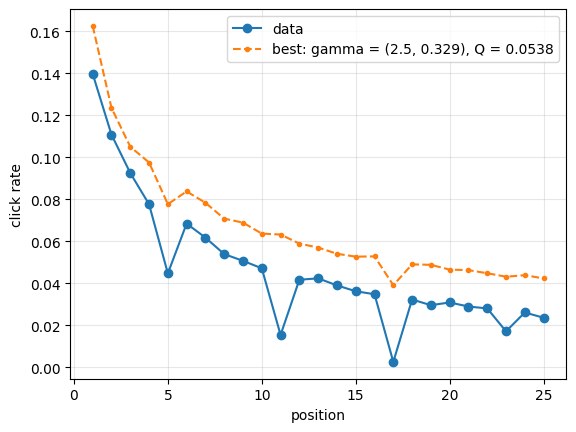

In [143]:
best = tab_grid_log.loc[tab_grid_log['Q'].idxmin()]
print(best)

a_data.groupby(level='j').mean().loc[1:25].plot(marker='o', label='data')
sim_click_rate(theta_log, X_log, best['gamma_0'], best['gamma_pos'], 'log', R=len(eps_draws)).loc[1:25].plot(
    ls='--', marker='.',
    label=f"best: gamma = ({best['gamma_0']}, {best['gamma_pos']}), Q = {best['Q']:.4f}")
plt.xlabel('position'); plt.ylabel('click rate')
plt.legend(); plt.grid(alpha=0.3); plt.show()

In [ ]:
### Export the estimates to LaTeX, in the style of project_one
# three columns: theta from purchases only, and its split into taste (beta) and search cost (gamma).
# gamma is zero on every attribute, so only the constant and log position differ between theta and beta.
from pathlib import Path
RES = Path('res'); RES.mkdir(exist_ok=True)

LABELS = {'log_price': 'Log price', 'stars': 'Star rating', 'review': 'Review score', 'prop_brand_bool': 'Chain',
          'prop_location_score1': 'Location score', 'position_log': 'Log position', 'constant': 'Constant'}
attrs = ['log_price', 'stars', 'review', 'prop_brand_bool', 'prop_location_score1']
split = ['position_log', 'constant']

gamma_est, beta_est = gamma_hat_fine, beta_hat_fine # the minimum of the fine grid
fmt = lambda x: f'{x:.3f}'
n_sess = df_rand.index.get_level_values('i').nunique()
n_hotels = int((df_rand.index.get_level_values('j') > 0).sum())

tex = [r'\begin{table}[htbp]', r'\centering', r'\caption{Demand and search cost estimates}', r'\label{tab:search_estimates}',
       r'\begin{tabular}{lccc}', r'\toprule',
       r' & (1) Purchases only & \multicolumn{2}{c}{(2) Purchases and clicks} \\', r'\cmidrule(lr){3-4}',
       r' & $\theta = \beta - \gamma$ & Utility $\beta$ & Search cost $\gamma$ \\', r'\midrule']
tex += [f'{LABELS[k]} & {fmt(theta_baseline[k])} & {fmt(beta_est[k])} & \\\\' for k in attrs]
tex.append(r'\midrule')
tex += [f'{LABELS[k]} & {fmt(theta_baseline[k])} & {fmt(beta_est[k])} & {fmt(gamma_est[k])} \\\\' for k in split]
tex += [r'\midrule',
        f'Sessions & {n_sess} & \\multicolumn{{2}}{{c}}{{{n_sess}}} \\\\',
        f'Hotel listings & {n_hotels} & \\multicolumn{{2}}{{c}}{{{n_hotels}}} \\\\',
        f'Simulation draws $R$ & & \\multicolumn{{2}}{{c}}{{{len(eps_draws)}}} \\\\',
        r'\bottomrule',
        r'\multicolumn{4}{p{0.9\linewidth}}{\footnotesize \textit{Note:} Random-ranking sessions only, sessions with a missing review score dropped. '
        r'Column (1) is a multinomial logit on bookings, which identifies only $\theta = \beta - \gamma$. '
        r'Column (2) splits $\theta$ with two-step simulated least squares on the clicks: $\gamma$ is chosen on a grid to match the click rates, and $\beta = \hat\theta + \hat\gamma$. '
        r'The search cost loads on the constant and log position only, so the attributes have the same coefficient in $\theta$ and $\beta$.} \\',
        r'\end{tabular}', r'\end{table}']

(RES / 'search_estimates.tex').write_text('\n'.join(tex) + '\n')
print('\n'.join(tex))


NameError: name 'gamma_hat_fine' is not defined

## Computing price equivalent (extended model)
The booking probability depends on $\theta = \beta - \gamma$ only, so the price equivalent of moving one position up is the same as in the simple model. The extended model splits it into a taste part ($\beta_{pos}$) and a search cost part ($-\gamma_{pos}$): moving up makes the hotel cheaper to search. The two parts add up to the simple model in log price.


In [ ]:
positions = range(2, 26)
parts = {
    'Total (theta)':  theta_log,                                                     # purchases only
    'Taste (beta)':   beta_hat,                                                      # beta_pos
    'Search cost':    pd.Series({'position_log': -gamma_hat['position_log'],        # -gamma_pos (mu enters with a minus)
                                 'log_price': beta_hat['log_price']}),
}
dlogp = pd.DataFrame({name: [price_change(c, p, pos_type='log') for p in positions] for name, c in parts.items()},
                     index=[f'{p} → {p-1}' for p in positions])
dlogp.index.name = 'Move'
assert np.allclose(dlogp['Taste (beta)'] + dlogp['Search cost'], dlogp['Total (theta)'])   # parts add up in logs

table_pe = (100 * (np.exp(dlogp) - 1)).round(1)        # price increase in %
table_pe
#table_pe.loc[['2 → 1', '3 → 2', '5 → 4', '10 → 9', '20 → 19']]

,Total (theta),Taste (beta),Search cost
Move,,,
2 → 1,49.0,22.1,22.1
3 → 2,26.3,12.4,12.4
4 → 3,18.0,8.6,8.6
5 → 4,13.7,6.6,6.6
6 → 5,11.1,5.4,5.4
7 → 6,9.3,4.5,4.5
8 → 7,8.0,3.9,3.9
9 → 8,7.0,3.4,3.4
10 → 9,6.2,3.1,3.1


In [ ]:
### Export the price equivalents of both models to LaTeX
moves = [2, 3, 4, 5, 10, 15, 20, 25] # the moves shown in the table: p -> p-1
rows = table_ext.loc[[f'{p} → {p-1}' for p in moves]]

tex = [r'\begin{table}[htbp]', r'\centering', r'\caption{Price equivalent of moving one position up}', r'\label{tab:price_equivalent}',
       r'\begin{tabular}{lccc}', r'\toprule',
       r' & (1) Purchases only & \multicolumn{2}{c}{(2) Purchases and clicks} \\', r'\cmidrule(lr){3-4}',
       r'Move & Total & Taste & Search cost \\', r'\midrule']
tex += [f'{p} $\\to$ {p-1} & {r["Simple logit"]:.1f} & {r["Taste"]:.1f} & {r["Search cost"]:.1f} \\\\'
        for p, (_, r) in zip(moves, rows.iterrows())]
tex += [r'\bottomrule',
        r'\multicolumn{4}{p{0.9\linewidth}}{\footnotesize \textit{Note:} The price increase in percent that keeps the booking probability constant when a hotel moves one position up, '
        r'$\Delta \log p = -\frac{\hat\theta_{pos}}{\hat\theta_{price}}\left[\log(r-1) - \log r\right]$. '
        r'Column (1) uses $\hat\theta$ from the logit on bookings. Column (2) splits it into the taste part, $\hat\beta_{pos}$, and the search cost part, $-\hat\gamma_{pos}$. '
        r'The two parts add up to column (1) in log price, not exactly in percent.} \\',
        r'\end{tabular}', r'\end{table}']

(RES / 'price_equivalent.tex').write_text('\n'.join(tex) + '\n')
print('\n'.join(tex))


\begin{table}[htbp]
\centering
\caption{Price equivalent of moving one position up}
\label{tab:price_equivalent}
\begin{tabular}{lccc}
\toprule
 & (1) Purchases only & \multicolumn{2}{c}{(2) Purchases and clicks} \\
\cmidrule(lr){3-4}
Move & Total & Taste & Search cost \\
\midrule
2 $\to$ 1 & 47.4 & 2.1 & 44.4 \\
3 $\to$ 2 & 25.5 & 1.2 & 24.0 \\
4 $\to$ 3 & 17.5 & 0.9 & 16.5 \\
5 $\to$ 4 & 13.3 & 0.7 & 12.5 \\
10 $\to$ 9 & 6.1 & 0.3 & 5.7 \\
15 $\to$ 14 & 3.9 & 0.2 & 3.7 \\
20 $\to$ 19 & 2.9 & 0.2 & 2.8 \\
25 $\to$ 24 & 2.3 & 0.1 & 2.2 \\
\bottomrule
\multicolumn{4}{p{0.9\linewidth}}{\footnotesize \textit{Note:} The price increase in percent that keeps the booking probability constant when a hotel moves one position up, $\Delta \log p = -\frac{\hat\theta_{pos}}{\hat\theta_{price}}\left[\log(r-1) - \log r\right]$. Column (1) uses $\hat\theta$ from the logit on bookings. Column (2) splits it into the taste part, $\hat\beta_{pos}$, and the search cost part, $-\hat\gamma_{pos}$. The two pa

## Markup (extended model)
The markup is $\eta_j = \frac{p_j}{\alpha(1-s_j)}$. The price coefficient is the same in both models ($\beta_{price} = \theta_{price}$, since $\gamma$ is zero on price), and the booking probabilities $s_j$ depend on $\theta = \beta - \gamma$ only. So the markup is the same as in the simple model.


In [ ]:
hotels_ext, summary_ext = compute_markups(theta_log, df_rand)
summary_ext.round(2).T

,price_usd,markup,mc,lerner
mean,164.57,144.43,20.14,0.88
median,125.01,110.25,15.17,0.88
